# Healthcare Predictive Analytics — Milestone 1
## Data Collection, Exploration & Preprocessing
**Dataset:** Diabetes 130-US Hospitals, 101,766 encounters.  
**Goal:** predict if a patient is readmitted within 30 days.

## 1. Data Collection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("diabetic_data.csv")

In [3]:
df.shape

(101766, 50)

In [4]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


The mapping file has 3 small tables stacked in one file. We read it line by line and split it into 3 dictionaries.

In [5]:
raw = pd.read_csv("IDS_mapping.csv", header=None, skip_blank_lines=False)

In [6]:
admission_type = {}
discharge = {}
source = {}
current = None

In [7]:
for i in range(len(raw)):
    first = raw.iloc[i, 0]
    second = raw.iloc[i, 1]
    if first == "admission_type_id":
        current = admission_type
    elif first == "discharge_disposition_id":
        current = discharge
    elif first == "admission_source_id":
        current = source
    elif pd.notna(first):
        current[int(first)] = second

In [8]:
print(len(admission_type), len(discharge), len(source))

8 30 25


## 2. Data Exploration

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [10]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


### 2.1 Missing values (written as `?` in this dataset)

In [11]:
missing = (df == "?").sum()

In [12]:
missing_pct = missing / len(df) * 100

In [13]:
missing_pct = missing_pct[missing_pct > 0]

In [14]:
missing_pct = missing_pct.sort_values(ascending=False)

In [15]:
missing_pct

weight               96.858479
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

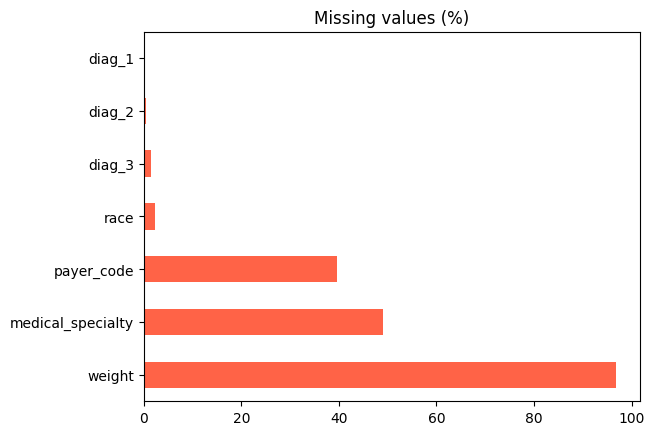

In [16]:
missing_pct.plot.barh(color="tomato")
plt.title("Missing values (%)")
plt.show()

**Findings:** `weight` is ~97% missing, `payer_code` and `medical_specialty` are ~40-50% missing.

### 2.2 Target (what we want to predict)

In [17]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

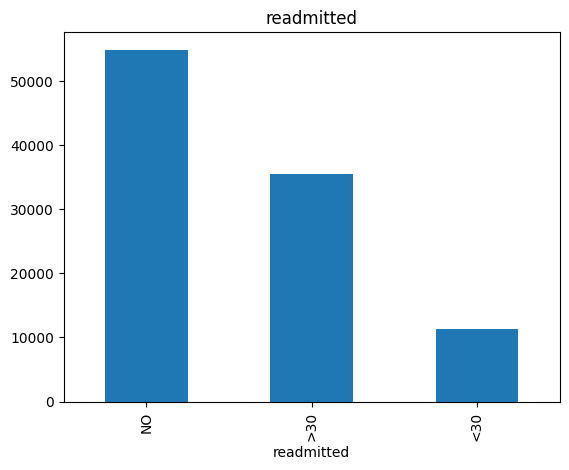

In [18]:
df["readmitted"].value_counts().plot.bar()
plt.title("readmitted")
plt.show()

**Finding:** only about 11% are readmitted within 30 days (`<30`). The target is **imbalanced**.

### 2.3 Numeric columns

In [19]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

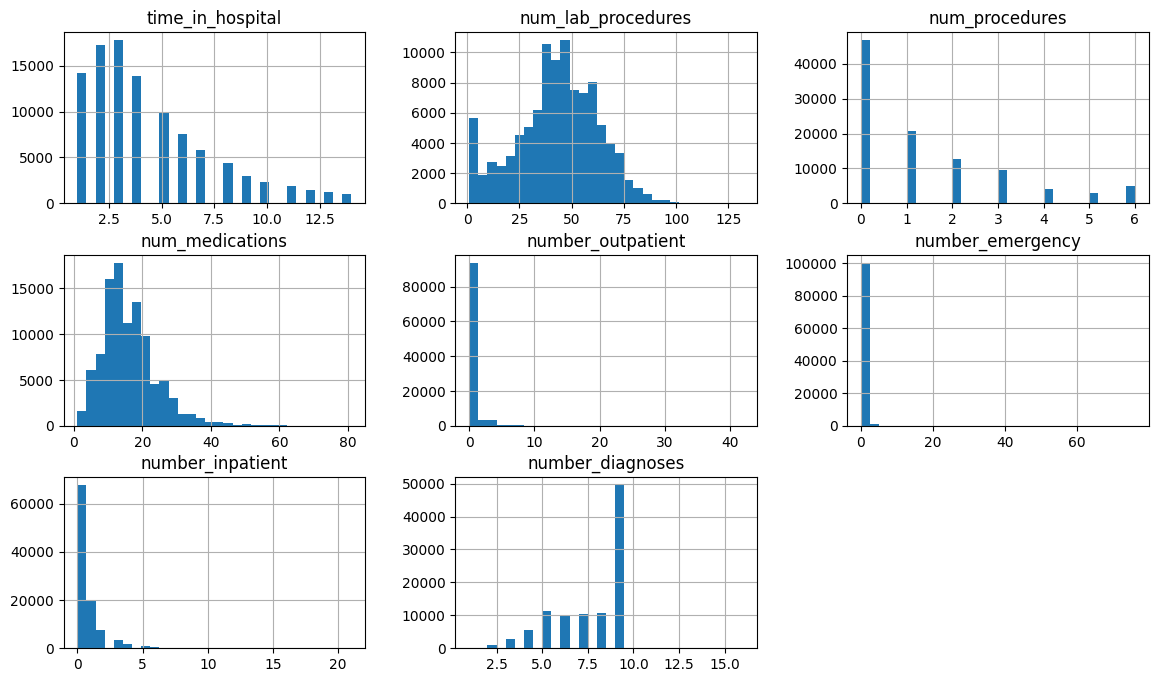

In [20]:
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.show()

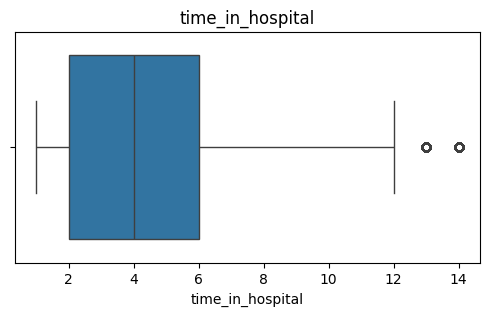

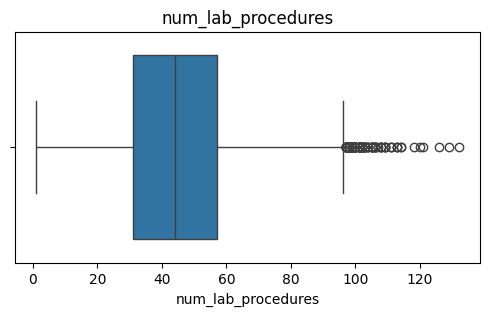

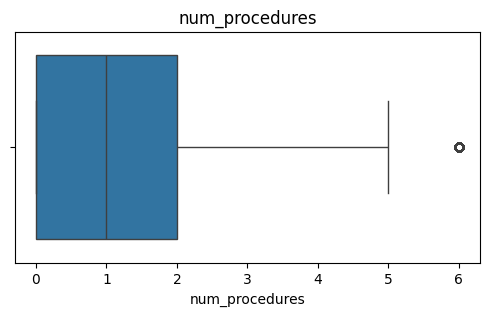

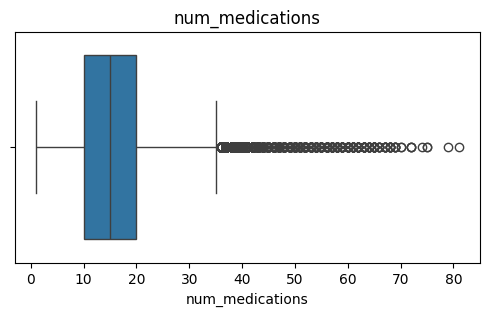

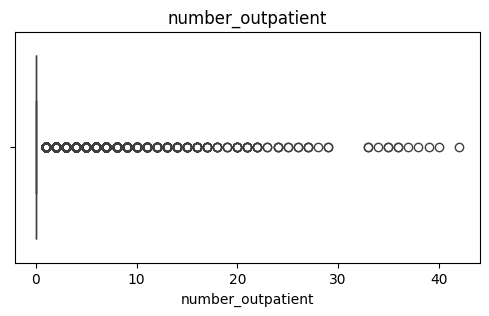

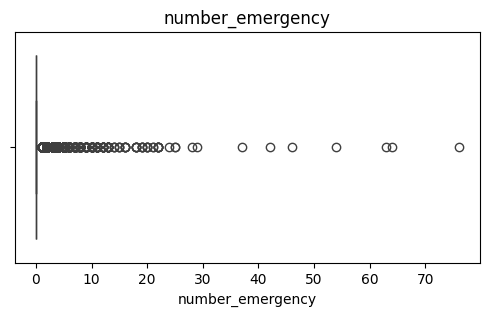

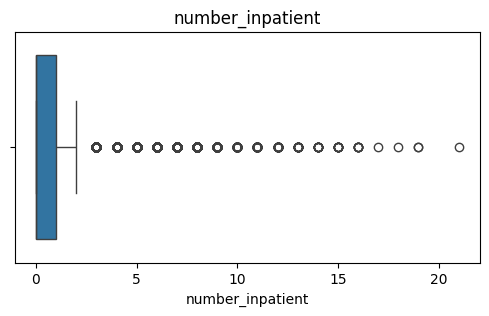

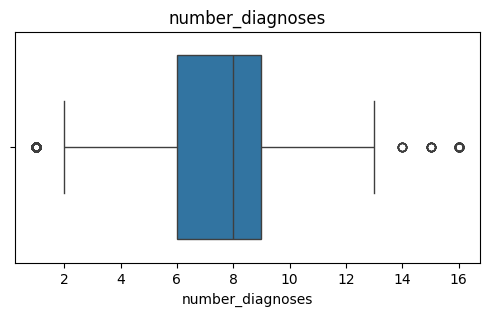

In [21]:
for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

**Finding:** `number_outpatient`, `number_emergency`, `number_inpatient` are very skewed (most are 0, a few are very large). We will cap the big values later.

### 2.4 Categorical columns

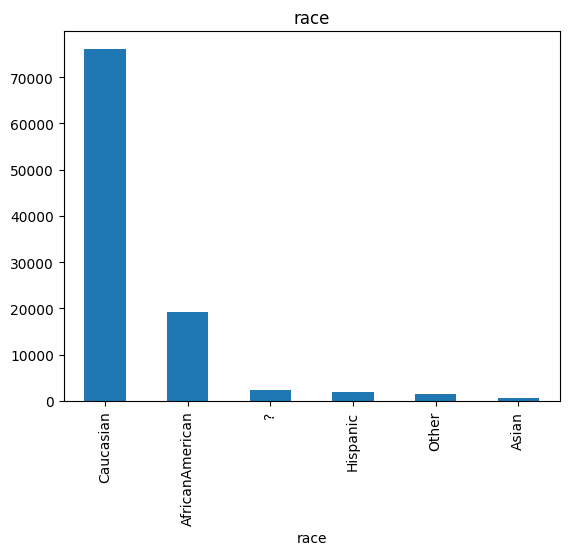

In [22]:
df["race"].value_counts().plot.bar()
plt.title("race")
plt.show()

In [23]:
df["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

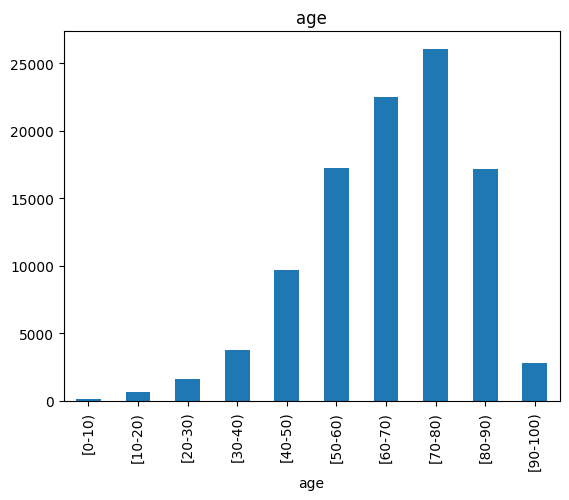

In [24]:
df["age"].value_counts().sort_index().plot.bar()
plt.title("age")
plt.show()

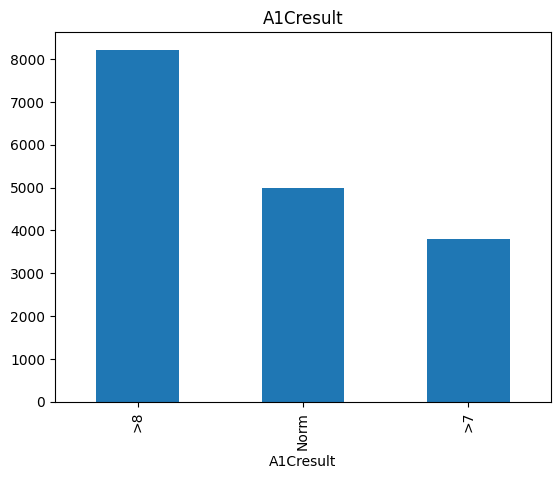

In [25]:
df["A1Cresult"].value_counts().plot.bar()
plt.title("A1Cresult")
plt.show()

### 2.5 Repeated patients

In [26]:
df["encounter_id"].nunique()

101766

In [27]:
df["patient_nbr"].nunique()

71518

In [28]:
df["patient_nbr"].duplicated().sum()

np.int64(30248)

**Finding:** some patients appear more than once. If we keep them all, the same patient can be in both train and test (data leakage). We will keep only the first visit of each patient.

### 2.6 Wrong / useless data

In [29]:
(df["gender"] == "Unknown/Invalid").sum()

np.int64(3)

In [30]:
dead = [11, 13, 14, 19, 20, 21]

In [31]:
df["discharge_disposition_id"].isin(dead).sum()

np.int64(2423)

In [32]:
df["examide"].value_counts()

examide
No    101766
Name: count, dtype: int64

In [33]:
df["citoglipton"].value_counts()

citoglipton
No    101766
Name: count, dtype: int64

**Findings:** 3 rows with invalid gender. About 2,400 patients died or went to hospice (they cannot be readmitted). `examide` and `citoglipton` have only one value, so they are useless.

## 3. Data Preprocessing

In [34]:
d = df.copy()

**3.1 Replace `?` with missing values**

In [35]:
d = d.replace("?", np.nan)

**3.2 Drop columns we don't need**

In [36]:
d = d.drop(columns=["weight", "payer_code", "examide", "citoglipton", "encounter_id"])

**3.3 Remove wrong rows**

In [37]:
d = d[d["gender"] != "Unknown/Invalid"]

In [38]:
d = d[~d["discharge_disposition_id"].isin(dead)]

**3.4 Keep only the first visit of each patient**

In [39]:
d = d.sort_values("patient_nbr")

In [40]:
d = d.drop_duplicates("patient_nbr", keep="first")

In [41]:
d.shape

(69987, 45)

**3.5 Fill missing text values with `Unknown`**

In [42]:
d["race"] = d["race"].fillna("Unknown")

In [43]:
d["medical_specialty"] = d["medical_specialty"].fillna("Unknown")

In [44]:
d["max_glu_serum"] = d["max_glu_serum"].fillna("Not tested")

In [45]:
d["A1Cresult"] = d["A1Cresult"].fillna("Not tested")

**3.6 Turn the ID columns into readable text using the mapping file**

In [46]:
d["admission_type"] = d["admission_type_id"].map(admission_type)

In [47]:
d["admission_type"] = d["admission_type"].fillna("Unknown")

In [48]:
d["discharge_text"] = d["discharge_disposition_id"].map(discharge)

In [49]:
d["admission_source"] = d["admission_source_id"].map(source)

The discharge text has many values, so we group them into 5 simple groups.

In [50]:
def discharge_group(i):
    if i == 1:
        return "Home"
    if i in [6, 8]:
        return "Home with service"
    if i in [3, 4, 5, 22, 23, 24, 30]:
        return "Facility"
    if i in [2, 9, 15, 16, 17, 27, 28, 29]:
        return "Other hospital"
    return "Unknown"

In [51]:
d["discharge_group"] = d["discharge_disposition_id"].apply(discharge_group)

In [52]:
d = d.drop(columns=["admission_type_id", "discharge_disposition_id", "admission_source_id", "discharge_text", "admission_source"])

**3.7 Medical specialty: keep the top 10, call the rest `Other`**

In [53]:
top10 = d["medical_specialty"].value_counts().index[:10]

In [54]:
d["medical_specialty"] = d["medical_specialty"].where(d["medical_specialty"].isin(top10), "Other")

**3.8 Diagnosis codes (ICD-9) → simple groups**

In [55]:
def diag_group(code):
    if pd.isna(code):
        return "Unknown"
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    n = float(code)
    if n >= 390 and n <= 459:
        return "Circulatory"
    if n >= 460 and n <= 519:
        return "Respiratory"
    if n >= 520 and n <= 579:
        return "Digestive"
    if int(n) == 250:
        return "Diabetes"
    if n >= 800 and n <= 999:
        return "Injury"
    if n >= 710 and n <= 739:
        return "Musculoskeletal"
    if n >= 580 and n <= 629:
        return "Genitourinary"
    if n >= 140 and n <= 239:
        return "Neoplasms"
    return "Other"

In [56]:
d["diag_1_group"] = d["diag_1"].apply(diag_group)

In [57]:
d["diag_2_group"] = d["diag_2"].apply(diag_group)

In [58]:
d["diag_3_group"] = d["diag_3"].apply(diag_group)

In [59]:
d = d.drop(columns=["diag_1", "diag_2", "diag_3"])

**3.9 Age: turn the range `[20-30)` into one number (the middle)**

In [60]:
age_map = {"[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95}

In [61]:
d["age_num"] = d["age"].map(age_map)

**3.10 Target: 1 if readmitted within 30 days, else 0**

In [62]:
d["readmit_30"] = (d["readmitted"] == "<30").astype(int)

In [63]:
d = d.drop(columns=["readmitted", "age"])

**3.11 Cap very big values (outliers) at the 99th percentile**

In [64]:
for col in ["number_outpatient", "number_emergency", "number_inpatient", "num_medications", "num_lab_procedures"]:
    limit = d[col].quantile(0.99)
    d[col] = d[col].clip(upper=limit)

**3.12 Medicine columns**  
We count how many medicines were used / changed, and drop medicines that are almost never used (<1%).

In [65]:
drug_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]

In [66]:
d["n_drugs_used"] = (d[drug_cols] != "No").sum(axis=1)

In [67]:
d["n_drugs_changed"] = d[drug_cols].isin(["Up", "Down"]).sum(axis=1)

In [68]:
for col in drug_cols:
    used = (d[col] != "No").mean()
    if used < 0.01:
        d = d.drop(columns=[col])

In [69]:
d["change"] = (d["change"] == "Ch").astype(int)

In [70]:
d["diabetesMed"] = (d["diabetesMed"] == "Yes").astype(int)

In [71]:
d.isna().sum().sum()

np.int64(0)

### 3.13 Save the cleaned dataset

In [72]:
d.to_csv("cleaned_diabetic_data.csv", index=False)

In [73]:
d.head()

,patient_nbr,race,gender,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,diabetesMed,admission_type,discharge_group,diag_1_group,diag_2_group,diag_3_group,age_num,readmit_30,n_drugs_used,n_drugs_changed
4267,135,Caucasian,Female,8,Cardiology,77,6,33,0,0,...,1,Urgent,Home,Circulatory,Injury,Digestive,55,1,3,1
5827,378,Caucasian,Female,2,Other,49,1,11,0,0,...,0,Elective,Home,Musculoskeletal,Other,Diabetes,55,0,0,0
67608,729,Caucasian,Female,4,InternalMedicine,68,2,23,0,0,...,1,Emergency,Facility,Injury,Respiratory,Other,85,0,1,0
17494,774,Caucasian,Female,3,InternalMedicine,46,0,20,0,0,...,1,Emergency,Home,Other,Circulatory,Circulatory,85,0,2,0
2270,927,AfricanAmerican,Female,5,InternalMedicine,49,0,5,0,0,...,1,Emergency,Home,Genitourinary,Neoplasms,Diabetes,35,0,1,0


In [74]:
d.shape

(69987, 33)

### 3.14 Encoding and scaling (model-ready dataset)

In [75]:
from sklearn.preprocessing import StandardScaler

In [76]:
y = d["readmit_30"]

In [77]:
X = d.drop(columns=["readmit_30", "patient_nbr"])

Text columns → numbers (one-hot encoding)

In [78]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

Scale the numeric columns (mean = 0, std = 1)

In [79]:
scale_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses", "n_drugs_used", "n_drugs_changed", "age_num"]

In [80]:
scaler = StandardScaler()

In [81]:
X[scale_cols] = scaler.fit_transform(X[scale_cols])

Note: in Milestone 3 we will fit the scaler on the training data only.

In [82]:
model_ready = pd.concat([X, y], axis=1)

In [83]:
model_ready.to_csv("model_ready_data.csv", index=False)

In [84]:
model_ready.shape

(69987, 98)

In [85]:
y.mean() * 100

np.float64(7.34850757997914)

## 4. Quick EDA on the cleaned data

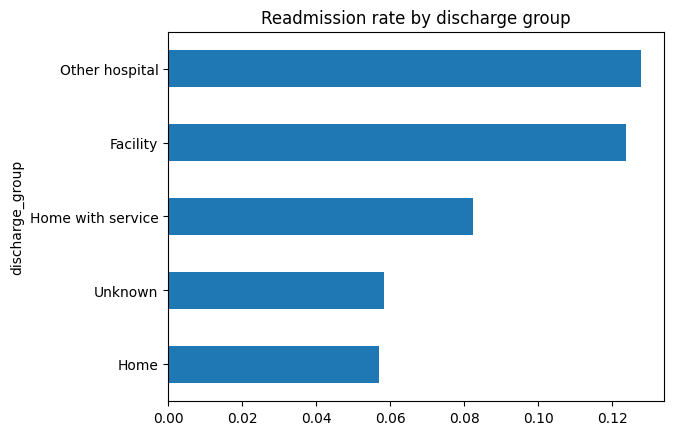

In [86]:
d.groupby("discharge_group")["readmit_30"].mean().sort_values().plot.barh()
plt.title("Readmission rate by discharge group")
plt.show()

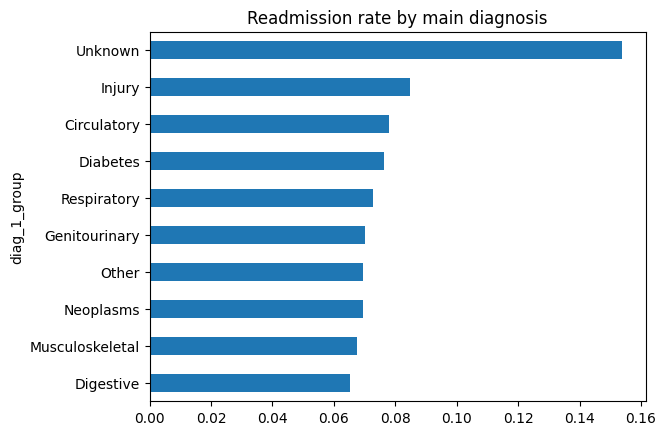

In [87]:
d.groupby("diag_1_group")["readmit_30"].mean().sort_values().plot.barh()
plt.title("Readmission rate by main diagnosis")
plt.show()

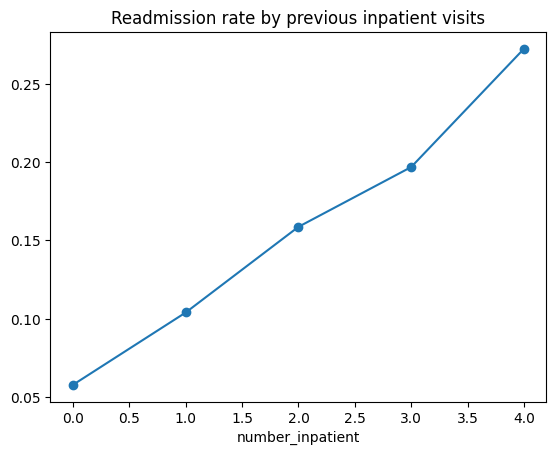

In [88]:
d.groupby("number_inpatient")["readmit_30"].mean().plot(marker="o")
plt.title("Readmission rate by previous inpatient visits")
plt.show()

In [89]:
corr_cols = ["age_num", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses", "n_drugs_used", "n_drugs_changed", "readmit_30"]

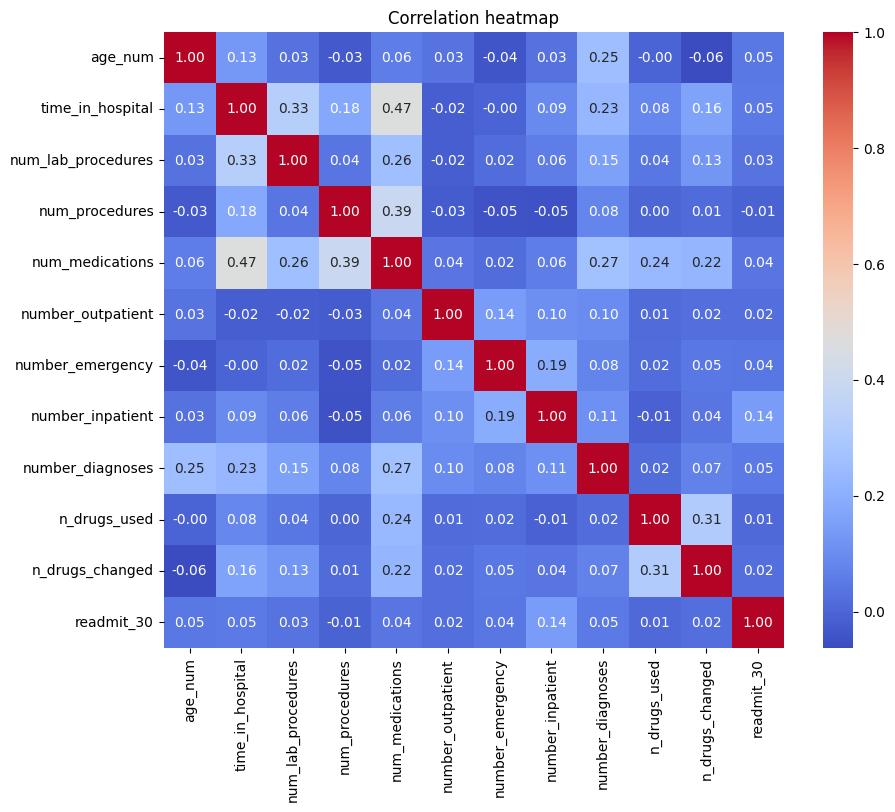

In [90]:
plt.figure(figsize=(10, 8))
sns.heatmap(d[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [91]:
d[corr_cols].corr()["readmit_30"].sort_values(ascending=False)

readmit_30            1.000000
number_inpatient      0.141796
time_in_hospital      0.051252
number_diagnoses      0.051028
age_num               0.048584
number_emergency      0.044336
num_medications       0.039313
num_lab_procedures    0.033740
n_drugs_changed       0.023839
number_outpatient     0.021781
n_drugs_used          0.008633
num_procedures       -0.008191
Name: readmit_30, dtype: float64

## 5. Summary
| Step | What we did |
|---|---|
| Missing values | dropped `weight` and `payer_code`; filled others with `Unknown` / `Not tested` |
| Wrong rows | removed invalid gender and patients who died / went to hospice |
| Repeated patients | kept the first visit only |
| Outliers | capped at the 99th percentile |
| Useless columns | dropped constant and very rare medicine columns |
| New features | diagnosis groups, discharge group, age number, number of drugs used/changed |
| Encoding / scaling | one-hot + StandardScaler |
| Target | `readmit_30` (about 7% are 1) |

Next: Milestone 2 — analysis, feature engineering and dashboards.